<b>Nama	: Bhima Fairul Rifqi <br>
NIM	: 26/579939/PPA/07301

Link Colab Notebook: https://drive.google.com/file/d/1YzM3pAv4R7vYFOBGj39-P-J2XTRkVU8J/view?usp=sharing <br>
Link GitHub: https://github.com/fairulrifqi/MKA-UGM-26-579939/tree/main/CVL/Tugas%203 </b>

# MOTSynth | NCC Template Matching vs Lucas–Kanade Optical Flow

**Cloud-ready notebooks:** Google Colab and Kaggle. Short English comments and reproducible tracking analysis.

**Two annotated videos:** `MOTSynth-000` (static camera), `MOTSynth-003` (moving camera). Every experiment uses a clip of at least 10 seconds. This is a **single-target, OTB-style one-pass evaluation (OPE)** applied to MOTSynth, **not** the OTB dataset. The initial bounding box is taken from the official ground truth; **subsequent ground truth is used only for evaluation**.

**Workflow:** source archives → automatic ROI → NCC and pyramidal LK (FB + MAD + refill) → CLE, Precision@20, success/AUC → six MP4s, figures, CSV and ZIP.

**Dataset facts:** MOTSynth provides 1,800-frame, 20-FPS, 1920×1080 original sequences. An optional 30-FPS nearest-frame resampling protocol is included to satisfy a 30-FPS assumption; duplicated frames contain no additional motion information. The default `FPS_PROTOCOL = "resample30"` evaluates the resampled timeline; use `"native20"` for original-data evaluation. FPS, image scaling and sampling are logged alongside the results.

**Download caveat:** The official MOTSynth video collection is packaged in large ZIP archives, not a Hugging Face collection of individually downloadable MP4s. This notebook first tries **HTTP-range ZIP access** to fetch only `000.mp4` and `003.mp4` from the first archive. This works **only if the server supports byte-range requests**. If the server does not support them, supply the MP4 files from a cloud drive or explicitly opt into the large full-archive download. Never assume the remote extraction succeeded without checking files.

**References:** [MOTSynth benchmark](https://motchallenge.net/data/MOTSynth-MOT-CVPR22/), [official preparation instructions](https://github.com/dvl-tum/motsynth-baselines/blob/main/docs/DATA_PREPARATION.md), [official MP4/frame conversion](https://github.com/dvl-tum/motsynth-baselines/blob/main/tools/anns/to_frames.py), [MOT ground-truth generator](https://github.com/dvl-tum/motsynth-baselines/blob/main/tools/anns/generate_mot_format_files.py), [OTB one-pass evaluation](https://doi.org/10.1109/TPAMI.2014.2388220).

## A. Data and evaluation protocol

- **Dataset**: MOTSynth (GTA V-generated synthetic pedestrians); `000` = static camera, `003` = moving camera.
- **Duration**: 15 seconds per sequence by default (`DURATION_SECONDS >= 10`). The selected 15-second window begins at an annotated target's first valid clip frame; a target is selected **automatically** from official track IDs. Targets are scored for annotation coverage and visible box quality.
- **Video FPS**: native 20 FPS; a configurable **30-FPS assumption** is implemented by nearest-frame temporal resampling, synchronizing every duplicated source frame to its original ground-truth annotation. Do not report this as native 30-FPS footage.
- **Frame/GT alignment**: official MOT annotations use **0-based** frame indices, x/y are stored 1-based; the official video-to-JPG converter skips the first two MP4 frames. Therefore `video_frame_index = gt_frame_index + 2` and coordinate origin is corrected by subtracting 1 pixel. This rule is configurable and visibly validated.
- **OTB protocol**: single initial GT bounding box, then OPE with **no ground-truth reset**. Only one pedestrian ID per video is evaluated. Tracking starts at a ground-truth box and all later ground truth is used solely for scoring/optional visualization.
- **Resolution**: tracking may operate on a resized frame for speed. **CLE and Precision@20 are computed back in original 1920×1080 pixel coordinates**. Success/AUC uses scale-independent box IoU.

**Important:** The evaluation uses the MOTSynth source data, **not OTB dataset sequences**. Selecting a target based on future annotated coverage is a dataset-selection rule, not a tracker correction.

## B. Template matching: normalized cross-correlation (NCC)

Let $T$ denote the fixed grayscale template initialized from the first ground-truth box, and $I_{x,y}$ the candidate patch in a local search window. Equation (1) is normalized cross-correlation:

$$
\boxed{
\operatorname{NCC}(T,I_{x,y}) =
\frac{\sum_{u,v}(T(u,v)-\overline{T})(I(x+u,y+v)-\overline{I}_{x,y})}
{\sqrt{\sum_{u,v}(T(u,v)-\overline{T})^2}
\sqrt{\sum_{u,v}(I(x+u,y+v)-\overline{I}_{x,y})^2}+\varepsilon}
} \tag{1}
$$

OpenCV `cv2.matchTemplate(..., cv2.TM_CCOEFF_NORMED)` computes the NCC map. The location of its maximum is the predicted top-left box. A constant-size template and a bounded search region are used for a transparent baseline. A low NCC confidence does not cause GT reinitialization.

## C. Optical flow: pyramidal Lucas–Kanade + FB, MAD, refill

For a small feature window $W$, brightness constancy gives $I_xu+I_yv=-I_t$. Lucas–Kanade solves the least-squares normal equations:

$$
\boxed{
\begin{bmatrix}
\sum_W I_x^2 & \sum_W I_xI_y\\
\sum_W I_xI_y & \sum_W I_y^2
\end{bmatrix}
\begin{bmatrix}u\\v\end{bmatrix}=
-\begin{bmatrix}\sum_W I_xI_t\\\sum_W I_yI_t\end{bmatrix}
} \tag{2}
$$

The practical tracker uses pyramidal `cv2.calcOpticalFlowPyrLK` with:

1. **Forward–backward (FB) check**: track $p_t\rightarrow p_{t+1}\rightarrow\hat p_t$; reject if $\lVert p_t-\hat p_t\rVert_2>\tau_{FB}$.
2. **MAD displacement filtering**: for displacement $d_i$, compute the component-wise median $m$ and MAD; reject large deviations using $\lvert d_i-m\rvert\leq \max(\tau_{min},k\cdot1.4826\operatorname{MAD})$.
3. **Robust box update**: translate the previous box by the median flow vector; keep a constant width and height.
4. **Feature refill**: if fewer than `MIN_FEATURES` survive, find new Shi–Tomasi corners **within the predicted ROI only**. The tracker never requests later GT boxes.

If all points fail, the last predicted box is held and the tracker attempts feature refill from that box; the failure is counted and not hidden.

## D. Evaluation metrics

For predicted box center $c_t=(x_t+w_t/2,y_t+h_t/2)$ and ground-truth center $c_t^{GT}$:

$$\mathrm{CLE}_t = \lVert c_t-c_t^{GT}\rVert_2,\qquad
\overline{\mathrm{CLE}}=\frac{1}{N}\sum_t\mathrm{CLE}_t.$$

$$\mathrm{Precision@20}=\frac{1}{N}\sum_t\mathbf{1}[\mathrm{CLE}_t\leq20\ \text{original-image pixels}].$$

$$\mathrm{IoU}_t=\frac{|B_t\cap B_t^{GT}|}{|B_t\cup B_t^{GT}|},\quad
S(\tau)=\frac{1}{N}\sum_t\mathbf{1}[\mathrm{IoU}_t>\tau],\quad
\mathrm{AUC}=\int_0^1 S(\tau)\,d\tau.$$

We report mean/median CLE, **Precision@20**, success rate at IoU 0.5, OTB-style **success AUC**, average IoU, and processing FPS. Undefined GT frames are excluded from the denominator and reported. Failure/hold states are retained in the timeline. AUC is approximated with a 101-point trapezoidal integration.

In [ ]:
# Minimal notebook dependencies
%pip -q install -U remotezip requests tqdm pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
# Colab: use /content for temporary high-speed processing.
PLATFORM = "Colab"
ROOT = "/content/motsynth_cvl_otb"
# Optional: from google.colab import drive; drive.mount('/content/drive')
# Set LOCAL_VIDEO_PATHS to MP4s on your mounted Drive if required.

In [ ]:
from pathlib import Path
import os, re, json, csv, time, math, shutil, zipfile, warnings, io
import configparser
import requests
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Video

SEQUENCE_IDS = {"static": "000", "moving": "003"}
DURATION_SECONDS = 15
FPS_PROTOCOL = "resample30"  # "resample30" or "native20"
ASSUMED_FPS = 30
NATIVE_FPS = 20
VIDEO_GT_OFFSET = 2          # Official video-to-frames converter skips 2 frames
PROCESS_WIDTH = 960         # Native 1920x1080 metrics are restored
SEARCH_RADIUS = 80
NCC_MIN_SCORE = 0.32
FB_THRESHOLD = 1.8
MAD_MULTIPLIER = 3.0
MIN_FEATURES = 18
MAX_FEATURES = 100
MIN_TRACK_COVERAGE = 0.85
SHOW_GROUND_TRUTH_IN_VIDEOS = True

# Set either file path to an existing cloud MP4 to bypass remote extraction.
LOCAL_VIDEO_PATHS = {"000": "", "003": ""}
# Point this to an existing annotation ZIP to bypass network download.
LOCAL_ANN_ZIP = ""
# Point this to an existing MOTSynth_1.zip if remote HTTP ranges fail.
LOCAL_VIDEO_ZIP = ""
ALLOW_FULL_VIDEO_ZIP = False  # Expensive: large archive, opt in explicitly
VIDEO_ZIP_URL = "https://motchallenge.net/data/MOTSynth_1.zip"
ANNOT_ZIP_URL = "https://motchallenge.net/data/MOTSynth_mot_annotations.zip"

assert DURATION_SECONDS >= 10
assert FPS_PROTOCOL in {"resample30", "native20"}
ROOT = Path(ROOT)
RAW = ROOT / "raw"
ANN = ROOT / "annotations"
RESULTS = ROOT / "results"
for folder in (RAW, ANN, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)
print("Platform:", PLATFORM, "| Root:", ROOT)
print("Sequence IDs:", SEQUENCE_IDS)
print("FPS protocol:", FPS_PROTOCOL, "| Native:", NATIVE_FPS, "| Assumption:", ASSUMED_FPS)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Platform: Colab | Root: /content/motsynth_cvl_otb
Sequence IDs: {'static': '000', 'moving': '003'}
FPS protocol: resample30 | Native: 20 | Assumption: 30


## 1. Fetch only two MP4s and their MOT annotations

Prefer range reads; use local cloud paths if the official server does not support remote ZIP access.

In [ ]:
from remotezip import RemoteZip


def locate_member(names, seq, leaf=None):
    seq = str(seq).zfill(3)
    matching = []
    for name in names:
        parts = Path(name).parts
        if leaf is None:
            if re.search(rf"(?:^|/){re.escape(seq)}\.mp4$", name, flags=re.I):
                matching.append(name)
        else:
            if leaf == "gt.txt" and len(parts) >= 3 and parts[-3:] == (seq, "gt", "gt.txt"):
                matching.append(name)
            if leaf == "seqinfo.ini" and len(parts) >= 2 and parts[-2:] == (seq, "seqinfo.ini"):
                matching.append(name)
    return sorted(matching, key=lambda n:(len(Path(n).parts),len(n)))


def copy_zip_member(z, name, destination):
    destination.parent.mkdir(parents=True, exist_ok=True)
    with z.open(name) as src, open(destination, "wb") as dst:
        shutil.copyfileobj(src, dst, length=1024 * 1024)
    if destination.stat().st_size == 0:
        raise RuntimeError(f"Empty archive member: {name}")
    print(f"Extracted {Path(name).name}: {destination.stat().st_size/1e6:.1f} MB")


def extract_required(z, mode):
    names = z.namelist()
    if mode == "videos":
        for seq in SEQUENCE_IDS.values():
            dest = RAW / f"{seq}.mp4"
            if dest.is_file() and dest.stat().st_size > 100_000:
                continue
            matches = locate_member(names, seq)
            if not matches:
                raise FileNotFoundError(f"{seq}.mp4 was not found in this video ZIP. Check archive selection.")
            copy_zip_member(z, matches[0], dest)
    elif mode == "annotations":
        for seq in SEQUENCE_IDS.values():
            for leaf in ("gt.txt", "seqinfo.ini"):
                dest = ANN / seq / ("gt/gt.txt" if leaf == "gt.txt" else leaf)
                if dest.is_file() and dest.stat().st_size > 0:
                    continue
                matches = locate_member(names, seq, leaf)
                if not matches:
                    raise FileNotFoundError(f"{seq}/{leaf} was not found in MOT annotation ZIP")
                copy_zip_member(z, matches[0], dest)


def download_stream(url, dest, max_gb=2):
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(dest.suffix + ".partial")
    with requests.get(url, stream=True, timeout=(20,120), allow_redirects=True) as r:
        r.raise_for_status()
        length = int(r.headers.get("Content-Length", 0))
        if length > max_gb * 1024**3:
            raise RuntimeError(f"Archive size {length/1024**3:.1f} GiB exceeds limit {max_gb} GiB")
        received = 0
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024*1024):
                if chunk:
                    received += len(chunk)
                    if received > max_gb * 1024**3:
                        raise RuntimeError("Download exceeded allowed disk budget")
                    f.write(chunk)
    tmp.replace(dest)
    return dest


def ensure_annotations():
    if all((ANN / seq / "gt/gt.txt").is_file() and
           (ANN / seq / "seqinfo.ini").is_file() for seq in SEQUENCE_IDS.values()):
        print("Annotation files already available")
        return
    src = Path(LOCAL_ANN_ZIP).expanduser() if LOCAL_ANN_ZIP else ANN / "MOTSynth_mot_annotations.zip"
    if src.is_file():
        with zipfile.ZipFile(src) as z:
            extract_required(z, "annotations")
        return
    try:
        print("Trying annotation ZIP by HTTP range...")
        with RemoteZip(ANNOT_ZIP_URL, timeout=45) as z:
            extract_required(z, "annotations")
        return
    except Exception as exc:
        print("Annotation ZIP partial access unavailable:", repr(exc))
    print("Downloading official annotation archive (bounded download)...")
    download_stream(ANNOT_ZIP_URL, src, max_gb=3)
    with zipfile.ZipFile(src) as z:
        extract_required(z, "annotations")


def ensure_videos():
    # Reuse pre-existing cloud MP4s, if supplied.
    for seq, p in LOCAL_VIDEO_PATHS.items():
        if p:
            src = Path(p).expanduser()
            if not src.is_file():
                raise FileNotFoundError(f"User-provided path does not exist: {src}")
            dst = RAW / f"{seq}.mp4"
            if src.resolve() != dst.resolve():
                shutil.copy2(src, dst)
    if all((RAW / f"{seq}.mp4").is_file() and (RAW / f"{seq}.mp4").stat().st_size > 100_000
           for seq in SEQUENCE_IDS.values()):
        print("Required videos already available")
        return
    if LOCAL_VIDEO_ZIP:
        src = Path(LOCAL_VIDEO_ZIP).expanduser()
        with zipfile.ZipFile(src) as z:
            extract_required(z, "videos")
        return
    try:
        print("Trying remote ZIP range access for only 000.mp4 + 003.mp4...")
        with RemoteZip(VIDEO_ZIP_URL, timeout=75) as z:
            extract_required(z, "videos")
        return
    except Exception as exc:
        print("Remote ZIP partial extraction unavailable:", repr(exc))
    if not ALLOW_FULL_VIDEO_ZIP:
        raise RuntimeError(
            "The official host did not allow selective remote ZIP extraction (or the request failed). "
            "This notebook will NOT silently download the enormous full video archive. "
            "Fix: set LOCAL_VIDEO_PATHS for 000.mp4 and 003.mp4 already in cloud storage, "
            "or set LOCAL_VIDEO_ZIP to an available MOTSynth_1.zip, "
            "or set ALLOW_FULL_VIDEO_ZIP=True if there is ample cloud disk space."
        )
    full_zip = RAW / "MOTSynth_1.zip"
    if not full_zip.is_file():
        print("Explicit full-video-archive download enabled. This may be very large.")
        download_stream(VIDEO_ZIP_URL, full_zip, max_gb=100)
    with zipfile.ZipFile(full_zip) as z:
        extract_required(z, "videos")

ensure_annotations()
ensure_videos()
for mode, seq in SEQUENCE_IDS.items():
    print(mode, seq, "MP4:", RAW / f"{seq}.mp4", "GT:", ANN / seq / "gt/gt.txt")

Trying annotation ZIP by HTTP range...
Extracted gt.txt: 5.3 MB
Extracted seqinfo.ini: 0.0 MB
Extracted gt.txt: 3.0 MB
Extracted seqinfo.ini: 0.0 MB
Trying remote ZIP range access for only 000.mp4 + 003.mp4...
Extracted 000.mp4: 277.3 MB
Extracted 003.mp4: 490.1 MB
static 000 MP4: /content/motsynth_cvl_otb/raw/000.mp4 GT: /content/motsynth_cvl_otb/annotations/000/gt/gt.txt
moving 003 MP4: /content/motsynth_cvl_otb/raw/003.mp4 GT: /content/motsynth_cvl_otb/annotations/003/gt/gt.txt


## 2. Select a persistent target and align GT

The source MP4 has two preliminary frames; the official GT uses 0-based frame indices.

In [ ]:
def load_annotations(seq):
    path = ANN / seq / "gt/gt.txt"
    df = pd.read_csv(path, header=None)
    if df.shape[1] < 9:
        raise ValueError(f"Unexpected MOT format in {path}: {df.shape[1]} columns")
    df = df.iloc[:,:9].copy()
    df.columns = ["frame", "id", "x", "y", "w", "h", "conf", "cls", "vis"]
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["frame", "id", "x", "y", "w", "h"])
    df = df[(df.conf > 0) & (df.cls == 1) & (df.w > 5) & (df.h > 10)].copy()
    df["frame"] = df["frame"].astype(int)
    df["id"] = df["id"].astype(int)
    df["x"] -= 1.0  # MOTSynth GT is 1-based in x/y
    df["y"] -= 1.0
    return df


def read_video_meta(seq):
    cap = cv2.VideoCapture(str(RAW / f"{seq}.mp4"))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open MP4 for sequence {seq}")
    info = {
        "total_frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "fps": float(cap.get(cv2.CAP_PROP_FPS)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    }
    cap.release()
    if info["fps"] <= 0 or info["width"] <= 0:
        raise RuntimeError(f"Invalid MP4 metadata: {info}")
    config = configparser.ConfigParser()
    config.read(ANN / seq / "seqinfo.ini")
    if config.has_section("Sequence"):
        info["annotation_fps"] = float(config.get("Sequence", "framerate", fallback="20"))
        info["is_moving"] = config.get("Sequence", "ismoving", fallback="?")
    else:
        info["annotation_fps"] = NATIVE_FPS
        info["is_moving"] = "?"
    if abs(info["fps"] - info["annotation_fps"]) > 0.6:
        warnings.warn(f"FPS mismatch for {seq}: MP4={info['fps']}, GT={info['annotation_fps']}")
    return info


def choose_target(df, info, window_native):
    # Prefer complete GT coverage without manually drawing a bounding box.
    earliest = max(0, int(df.frame.min()))
    possible_starts = sorted(set([earliest, 0] + list(range(0, min(1201, int(df.frame.max())-window_native+2), 20))))
    candidates = []
    usable = df[(df.vis.fillna(1) >= 0.15) & (df.w >= 20) & (df.h >= 45)]
    for start in possible_starts:
        stop = start + window_native
        if VIDEO_GT_OFFSET + stop > info["total_frames"]:
            continue
        sub = usable[(usable.frame >= start) & (usable.frame < stop)]
        if sub.empty:
            continue
        for tid, grp in sub.groupby("id"):
            at_start = grp[grp.frame == start]
            if at_start.empty:
                continue
            coverage = grp.frame.nunique() / window_native
            median_h = float(grp.h.median())
            median_w = float(grp.w.median())
            if median_h < 65 or median_w < 24:
                continue
            score = 10*coverage + 0.5*float(grp.vis.median()) + 0.001*median_h - start*0.0001
            candidates.append((score, coverage, start, int(tid)))
    if not candidates:
        raise RuntimeError("No sufficiently persistent GT track. Try a shorter duration (>=10 s) or another video.")
    candidates.sort(reverse=True)
    score, coverage, start, tid = candidates[0]
    if coverage < MIN_TRACK_COVERAGE:
        raise RuntimeError(f"Best GT coverage is {coverage:.1%}; below {MIN_TRACK_COVERAGE:.0%} threshold")
    return start, tid, coverage


DATA = {}
for label, seq in SEQUENCE_IDS.items():
    info = read_video_meta(seq)
    gt = load_annotations(seq)
    native_window = round(DURATION_SECONDS * info["annotation_fps"])
    start, target_id, coverage = choose_target(gt, info, native_window)
    target_gt = gt[gt.id == target_id].drop_duplicates("frame").set_index("frame")
    eval_fps = ASSUMED_FPS if FPS_PROTOCOL == "resample30" else info["annotation_fps"]
    eval_steps = round(DURATION_SECONDS * eval_fps)
    lookup = np.floor((np.arange(eval_steps) + 0.00001) * info["annotation_fps"] / eval_fps + 0.5).astype(int)
    lookup = np.minimum(lookup, native_window-1) + start
    native_frames = lookup.tolist()
    boxes = {}
    for frame_idx in sorted(set(native_frames)):
        if frame_idx in target_gt.index:
            r = target_gt.loc[frame_idx]
            boxes[frame_idx] = np.array([r.x, r.y, r.w, r.h], dtype=float)
    assert native_frames[0] in boxes, "Initial GT missing"
    DATA[label] = {
        "seq": seq, "meta": info, "gt": boxes, "lookup": native_frames,
        "start": start, "target_id": target_id, "coverage": coverage,
        "fps": float(eval_fps), "frame_count": len(native_frames)
    }
    print(f"{label.upper()} | sequence={seq} | ID={target_id} | "
          f"{DURATION_SECONDS}s | evaluation={eval_fps:g} fps | "
          f"GT coverage={coverage:.1%} | GT start={start} | "
          f"MP4 FPS={info['fps']:.2f} | camera moving={info['is_moving']}")

STATIC | sequence=000 | ID=58 | 15s | evaluation=30 fps | GT coverage=100.0% | GT start=100 | MP4 FPS=20.00 | camera moving=0
MOVING | sequence=003 | ID=11 | 15s | evaluation=30 fps | GT coverage=97.3% | GT start=960 | MP4 FPS=20.00 | camera moving=1


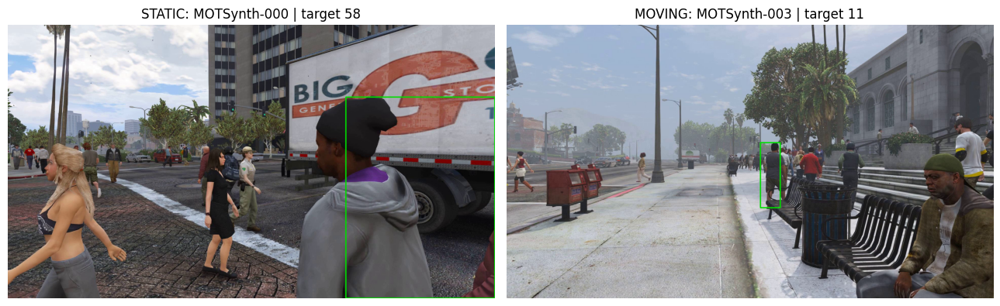

In [ ]:
from IPython.display import display

def read_motsynth_frame(seq, native_frame):
    cap = cv2.VideoCapture(str(RAW / f"{seq}.mp4"))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(native_frame + VIDEO_GT_OFFSET))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Cannot read frame {native_frame} from sequence {seq}")
    return frame

fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax, (label, sample) in zip(axes, DATA.items()):
    frame = read_motsynth_frame(sample["seq"], sample["lookup"][0])
    bbox = sample["gt"][sample["lookup"][0]]
    x,y,w,h = [int(round(v)) for v in bbox]
    cv2.rectangle(frame, (x,y), (x+w,y+h), (0,220,0), 4)
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{label.upper()}: MOTSynth-{sample['seq']} | target {sample['target_id']}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "source_first_frames.png", dpi=150)
plt.show()

## 3. Tracking algorithms

The original template and the first LK feature set come from the same GT initialization box.

In [ ]:
def clamp_box(box, W, H):
    x, y, w, h = [float(q) for q in box]
    w, h = min(max(w, 2), W), min(max(h, 2), H)
    x = float(np.clip(x, 0, max(W-w,0)))
    y = float(np.clip(y, 0, max(H-h,0)))
    return np.array([x,y,w,h], dtype=float)


def resize_frame(frame, width):
    h0, w0 = frame.shape[:2]
    if width <= 0 or width >= w0:
        return frame, 1., 1.
    h1 = max(2, int(round(h0*width/w0)))
    out = cv2.resize(frame, (width,h1), interpolation=cv2.INTER_AREA)
    return out, width/w0, h1/h0


def scale_box(box, sx, sy):
    return np.array([box[0]*sx, box[1]*sy, box[2]*sx, box[3]*sy],dtype=float)


def unscale_box(box,sx,sy):
    return np.array([box[0]/sx,box[1]/sy,box[2]/sx,box[3]/sy],dtype=float)


class NCCTracker:
    def __init__(self, frame, box):
        self.gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
        H,W = self.gray.shape
        self.box = clamp_box(box,W,H)
        x,y,w,h = [int(round(v)) for v in self.box]
        self.template = self.gray[y:y+h,x:x+w].copy()
        if self.template.shape[0] < 6 or self.template.shape[1] < 6:
            raise RuntimeError("Template ROI too small")
        self.box[2:] = (self.template.shape[1],self.template.shape[0])
        self.status = "init"
        self.quality = 1.

    def update(self,frame):
        gray = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
        H,W=gray.shape
        x,y,w,h = [int(round(v)) for v in self.box]
        x0=max(0,x-SEARCH_RADIUS); y0=max(0,y-SEARCH_RADIUS)
        x1=min(W,x+w+SEARCH_RADIUS); y1=min(H,y+h+SEARCH_RADIUS)
        patch=gray[y0:y1,x0:x1]
        if patch.shape[0] < self.template.shape[0] or patch.shape[1] < self.template.shape[1]:
            self.status="invalid_roi"; self.quality=float('nan')
            return self.box.copy()
        result = cv2.matchTemplate(patch,self.template,cv2.TM_CCOEFF_NORMED)
        _, best, _, loc=cv2.minMaxLoc(result)
        self.quality=float(best)
        if np.isfinite(best) and best>=NCC_MIN_SCORE:
            self.box[:2] = [x0+loc[0],y0+loc[1]]
            self.box = clamp_box(self.box,W,H)
            self.status="tracked"
        else:
            self.status="low_ncc_hold"
        return self.box.copy()


class LKTracker:
    def __init__(self,frame,box):
        self.gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
        H,W=self.gray.shape
        self.box=clamp_box(box,W,H)
        self.params=dict(winSize=(19,19),maxLevel=3,
                         criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,30,0.01))
        self.points=self._corners(self.gray,self.box)
        self.status="init"; self.quality=len(self.points)

    def _corners(self,gray,box,existing=None):
        H,W=gray.shape
        mask=np.zeros((H,W),dtype=np.uint8)
        x,y,w,h = [int(round(v)) for v in clamp_box(box,W,H)]
        margin=max(2,min(8,w//8,h//8))
        if (x+w-margin) <= (x+margin) or (y+h-margin) <= (y+margin):
            return np.empty((0,1,2),dtype=np.float32)
        mask[y+margin:y+h-margin,x+margin:x+w-margin]=255
        if existing is not None and len(existing):
            for px,py in existing.reshape(-1,2):
                cv2.circle(mask,(int(round(px)),int(round(py))),8,0,-1)
        corners=cv2.goodFeaturesToTrack(gray,maxCorners=MAX_FEATURES,qualityLevel=0.01,
                                        minDistance=7,mask=mask,blockSize=5)
        return corners.astype(np.float32) if corners is not None else np.empty((0,1,2),np.float32)

    def _refill(self,gray):
        if len(self.points)>=MIN_FEATURES:
            return
        new=self._corners(gray,self.box,self.points)
        if len(new):
            remain=max(0,MAX_FEATURES-len(self.points))
            self.points=np.concatenate((self.points,new[:remain]),axis=0)

    def update(self,frame):
        gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
        H,W=gray.shape
        tracked=np.empty((0,1,2),np.float32)
        quality=0
        if len(self.points):
            forward,s1,_=cv2.calcOpticalFlowPyrLK(self.gray,gray,self.points,None,**self.params)
            if forward is not None and s1 is not None:
                backward,s2,_=cv2.calcOpticalFlowPyrLK(gray,self.gray,forward,None,**self.params)
                if backward is not None and s2 is not None:
                    old=self.points.reshape(-1,2)
                    new=forward.reshape(-1,2)
                    rev=backward.reshape(-1,2)
                    fb=np.linalg.norm(old-rev,axis=1)
                    good=(s1.reshape(-1)==1)&(s2.reshape(-1)==1)&(fb<=FB_THRESHOLD)
                    good &= np.isfinite(old).all(1)&np.isfinite(new).all(1)
                    shifts=new[good]-old[good]
                    if len(shifts):
                        median=np.median(shifts,axis=0)
                        mad=np.median(np.abs(shifts-median),axis=0)
                        limit=np.maximum(1.5,MAD_MULTIPLIER*1.4826*mad)
                        inliers=(np.abs(shifts-median)<=limit).all(axis=1)
                        shifts=shifts[inliers]
                        tracked=new[good][inliers].reshape(-1,1,2).astype(np.float32)
                        if len(shifts):
                            delta=np.median(shifts,axis=0)
                            self.box[:2]+=delta
                            self.box=clamp_box(self.box,W,H)
                            quality=len(shifts)
        self.points=tracked
        self.status="tracked" if quality else "no_flow_hold"
        self._refill(gray)
        if quality and len(self.points)<MIN_FEATURES:
            self.status="tracked_refill_needed"
        elif quality and len(self.points)>=MIN_FEATURES:
            self.status="tracked_refilled"
        elif len(self.points):
            self.status="no_flow_refilled"
        self.quality=int(quality)
        self.gray=gray
        return self.box.copy()

In [ ]:
def iou_xywh(a,b):
    ax,ay,aw,ah=a; bx,by,bw,bh=b
    ix=max(0,min(ax+aw,bx+bw)-max(ax,bx))
    iy=max(0,min(ay+ah,by+bh)-max(ay,by))
    inter=ix*iy
    union=aw*ah+bw*bh-inter
    return inter/union if union>0 else 0.


def evaluate_frame(pred,gt):
    if gt is None:
        return float('nan'),float('nan')
    pred=np.asarray(pred);gt=np.asarray(gt)
    pc=pred[:2]+pred[2:]/2
    gc=gt[:2]+gt[2:]/2
    return float(np.linalg.norm(pc-gc)),float(iou_xywh(pred,gt))


def summarize(df):
    valid=df[df["cle_px"].notna()].copy()
    if valid.empty:
        return {"n_valid":0}
    tau=np.linspace(0.,1.,101)
    overlap=valid["iou"].to_numpy(float)
    curve=np.array([(overlap>t).mean() for t in tau])
    auc=float(np.trapezoid(curve,tau)) if hasattr(np,"trapezoid") else float(np.trapz(curve,tau))
    return {
        "n_valid":len(valid),
        "GT_coverage":len(valid)/len(df),
        "CLE_mean_px":valid.cle_px.mean(),
        "CLE_median_px":valid.cle_px.median(),
        "Precision@20":float((valid.cle_px<=20.).mean()),
        "Success@0.5":float((overlap>0.5).mean()),
        "Success_AUC":auc,
        "IoU_mean":float(overlap.mean()),
        "hold_rate":float((valid.status.astype(str).str.contains("hold")).mean()),
        "fps_algorithm":float(len(df)/max(df.runtime_ms.sum()/1000,1e-6))
    }


def _draw_box(frame,box,color,label):
    if box is None:return
    x,y,w,h=[int(round(v)) for v in box]
    cv2.rectangle(frame,(x,y),(x+w,y+h),color,2)
    cv2.putText(frame,label,(max(2,x),max(20,y-7)),cv2.FONT_HERSHEY_SIMPLEX,0.56,color,2)


def _video_writer(path,fps,size):
    writer=cv2.VideoWriter(str(path),cv2.VideoWriter_fourcc(*"mp4v"),fps,size)
    if not writer.isOpened():
        raise RuntimeError(f"MP4 writer failed: {path}")
    return writer

## 4. Run both trackers on both videos

No future ground-truth boxes are supplied to the trackers.

In [ ]:
def run_video(label,sample):
    seq=sample["seq"]
    first_native=sample["lookup"][0]
    first_orig=read_motsynth_frame(seq,first_native)
    first,sx,sy=resize_frame(first_orig,PROCESS_WIDTH)
    H,W=first.shape[:2]
    gt0=sample["gt"][first_native]
    init_box=scale_box(gt0,sx,sy)
    trackers={"NCC":NCCTracker(first,init_box),"LK":LKTracker(first,init_box)}
    paths={
        "NCC":RESULTS/f"MOTSynth_{seq}_{label}_NCC.mp4",
        "LK":RESULTS/f"MOTSynth_{seq}_{label}_LK.mp4",
        "comparison":RESULTS/f"MOTSynth_{seq}_{label}_comparison.mp4"
    }
    writers={k:_video_writer(paths[k],sample["fps"],(W,H)) for k in ["NCC","LK"]}
    comparison_writer=_video_writer(paths["comparison"],sample["fps"],(W*2,H))
    rows=[]
    cap=cv2.VideoCapture(str(RAW/f"{seq}.mp4"))
    if not cap.isOpened():
        raise RuntimeError(f"Unable to open MOTSynth {seq}")
    current_index=None
    current_frame=None
    try:
        for t,idx in enumerate(tqdm(sample["lookup"],desc=f"{label}: {seq}")):
            # Reuse source frame when resampling creates duplicate time steps.
            if idx != current_index:
                absolute=int(idx+VIDEO_GT_OFFSET)
                if current_index is None or absolute != current_index+VIDEO_GT_OFFSET+1:
                    cap.set(cv2.CAP_PROP_POS_FRAMES,absolute)
                ok,frame_orig=cap.read()
                if not ok:
                    raise RuntimeError(f"MP4 frame read failed at GT={idx} (video={absolute})")
                current_frame,_,_=resize_frame(frame_orig,PROCESS_WIDTH)
                current_index=idx
            frame=current_frame
            gt=sample["gt"].get(idx)
            gt_small=scale_box(gt,sx,sy) if gt is not None else None
            vis={}
            for method,tracker in trackers.items():
                tick=time.perf_counter()
                pred_small=tracker.box.copy() if t==0 else tracker.update(frame)
                elapsed_ms=(time.perf_counter()-tick)*1000
                pred_orig=unscale_box(pred_small,sx,sy)
                cle,iou=evaluate_frame(pred_orig,gt)
                rows.append({
                    "condition":label,"sequence":seq,"target_id":sample["target_id"],
                    "method":method,"step":t,"time_s":t/sample["fps"],
                    "native_gt_frame":idx,"cle_px":cle,"iou":iou,
                    "status":tracker.status,"quality":tracker.quality,
                    "runtime_ms":elapsed_ms,
                    "pred_x":pred_orig[0],"pred_y":pred_orig[1],
                    "pred_w":pred_orig[2],"pred_h":pred_orig[3],
                    "gt_x":gt[0] if gt is not None else np.nan,
                    "gt_y":gt[1] if gt is not None else np.nan,
                    "gt_w":gt[2] if gt is not None else np.nan,
                    "gt_h":gt[3] if gt is not None else np.nan
                })
                canvas=frame.copy()
                if SHOW_GROUND_TRUTH_IN_VIDEOS and gt_small is not None:
                    _draw_box(canvas,gt_small,(60,220,60),"GT")
                _draw_box(canvas,pred_small,(25,30,245) if method=="NCC" else (245,160,25),method)
                caption=f"{label.upper()} | {method} | {t/sample['fps']:.1f}s | IoU={iou:.2f} | {tracker.status}"
                cv2.putText(canvas,caption,(12,26),cv2.FONT_HERSHEY_SIMPLEX,0.53,(255,255,255),3)
                cv2.putText(canvas,caption,(12,26),cv2.FONT_HERSHEY_SIMPLEX,0.53,(20,20,20),1)
                writers[method].write(canvas)
                vis[method]=canvas
            comparison_writer.write(np.concatenate([vis["NCC"],vis["LK"]],axis=1))
    finally:
        cap.release()
        for wr in writers.values():wr.release()
        comparison_writer.release()
    df=pd.DataFrame(rows)
    df.to_csv(RESULTS/f"MOTSynth_{seq}_{label}_frame_metrics.csv",index=False)
    return df,paths

ALL_METRICS=[]
all_videos={}
for condition,sample in DATA.items():
    result,files=run_video(condition,sample)
    ALL_METRICS.append(result)
    all_videos[condition]=files
frame_metrics=pd.concat(ALL_METRICS,ignore_index=True)
frame_metrics.to_csv(RESULTS/"all_frame_metrics.csv",index=False)
print("Saved",len(frame_metrics),"tracker-frame observations")

static: 000:   0%|          | 0/450 [00:00<?, ?it/s]

moving: 003:   0%|          | 0/450 [00:00<?, ?it/s]

Saved 1800 tracker-frame observations


## 5. Precision, success and AUC

,condition,seq,method,duration_s,eval_fps,native_fps,processing_width,n_valid,GT_coverage,CLE_mean_px,CLE_median_px,Precision@20,Success@0.5,Success_AUC,IoU_mean,hold_rate,fps_algorithm
0,moving,003,LK,15,30.0,20.0,960,450,1.0,987.0728,1229.1001,0.0133,0.0200,0.0232,0.0232,0.0000,108.5836
1,moving,003,NCC,15,30.0,20.0,960,450,1.0,370.9906,419.3256,0.0267,0.0267,0.0414,0.0415,0.1222,330.7756
2,static,000,LK,15,30.0,20.0,960,450,1.0,1217.9572,1331.9969,0.0022,0.0089,0.0157,0.0156,0.0000,146.7582
3,static,000,NCC,15,30.0,20.0,960,450,1.0,1085.7615,1237.4005,0.0089,0.0267,0.0383,0.0382,0.0133,132.4073


MOVING / MOTSynth-003: highest AUC = NCC (0.041); lowest CLE = NCC (370.99 px); highest Precision@20 = NCC (0.027).
STATIC / MOTSynth-000: highest AUC = NCC (0.038); lowest CLE = NCC (1085.76 px); highest Precision@20 = NCC (0.009).


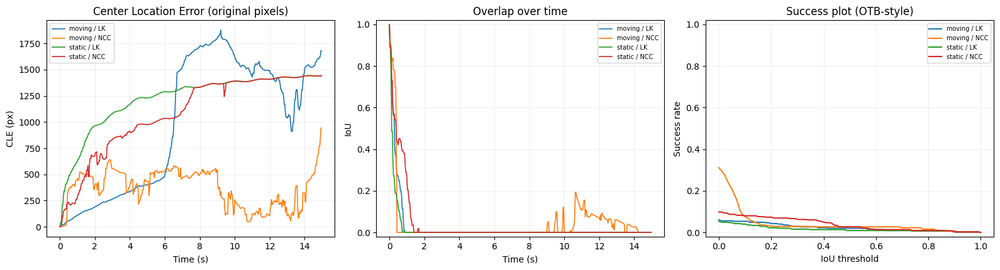

In [ ]:
SUMMARY=[]
for (condition,method),subset in frame_metrics.groupby(["condition","method"],sort=True):
    meta=DATA[condition]
    SUMMARY.append({"condition":condition,"seq":meta["seq"],"method":method,
                    "duration_s":DURATION_SECONDS,"eval_fps":meta["fps"],
                    "native_fps":meta["meta"]["annotation_fps"],
                    "processing_width":PROCESS_WIDTH,
                    **summarize(subset)})
summary=pd.DataFrame(SUMMARY).sort_values(["condition","method"])
summary.to_csv(RESULTS/"comparison_summary.csv",index=False)
display(summary.round(4))

comparison_sentences=[]
for condition, subset in summary.groupby("condition"):
    best_auc=subset.loc[subset.Success_AUC.idxmax()]
    best_cle=subset.loc[subset.CLE_mean_px.idxmin()]
    best_precision=subset.loc[subset["Precision@20"].idxmax()]
    line=(f"{condition.upper()} / MOTSynth-{best_auc.seq}: highest AUC = "
          f"{best_auc.method} ({best_auc.Success_AUC:.3f}); "
          f"lowest CLE = {best_cle.method} ({best_cle.CLE_mean_px:.2f} px); "
          f"highest Precision@20 = {best_precision.method} ({best_precision['Precision@20']:.3f}).")
    comparison_sentences.append(line)
    print(line)

fig,axes=plt.subplots(1,3,figsize=(16,4.4))
for (condition,method),df in frame_metrics.groupby(["condition","method"]):
    key=f"{condition} / {method}"
    axes[0].plot(df.time_s,df.cle_px,label=key,linewidth=1.2)
    axes[1].plot(df.time_s,df.iou,label=key,linewidth=1.2)
    vals=df.iou.dropna().to_numpy(float)
    tau=np.linspace(0.,1.,101)
    axes[2].plot(tau,[(vals>t).mean() for t in tau],label=key)
axes[0].set(title="Center Location Error (original pixels)",xlabel="Time (s)",ylabel="CLE (px)")
axes[1].set(title="Overlap over time",xlabel="Time (s)",ylabel="IoU",ylim=(-.02,1.02))
axes[2].set(title="Success plot (OTB-style)",xlabel="IoU threshold",ylabel="Success rate",ylim=(-.02,1.02))
for ax in axes:
    ax.grid(True,alpha=.2)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(RESULTS/"tracking_metrics.png",dpi=170)
plt.show()

## 6. Cell 11 — H.264 browser-compatible preview and ZIP export

OpenCV initially writes `mp4v` files that may display as black video with `0:00` in browsers. This cell automatically transcodes all six output MP4s to H.264 (`yuv420p`, faststart), validates duration/codec, and preserves the corrected preview syntax: `Video(str(video_path), embed=True, width=900)`. For an already completed run, rerun only this cell to repair the existing output files and rebuild the ZIP.

In [ ]:
# Cell 11: H.264 repair, comparison previews, and ZIP export
from IPython.display import display, Video
import subprocess, shutil, json, zipfile


def verify_browser_video(video_path):
    """Convert OpenCV's MPEG-4 Part 2 MP4 to browser-compatible H.264."""
    video_path = Path(video_path)
    if not video_path.is_file() or video_path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty video: {video_path}")

    ffmpeg = shutil.which("ffmpeg")
    ffprobe = shutil.which("ffprobe")
    if not ffmpeg or not ffprobe:
        raise RuntimeError("FFmpeg and ffprobe are required for browser playback.")

    check = subprocess.run(
        [ffprobe, "-v", "error", "-select_streams", "v:0",
         "-show_entries", "stream=codec_name,pix_fmt:format=duration",
         "-of", "json", str(video_path)],
        capture_output=True, text=True, check=True
    )
    info = json.loads(check.stdout)
    streams = info.get("streams", [])
    duration = float(info.get("format", {}).get("duration", 0))
    if not streams or duration <= 0:
        raise RuntimeError(f"Invalid video stream or duration: {video_path}")
    codec = streams[0].get("codec_name", "")
    pix_fmt = streams[0].get("pix_fmt", "")
    if codec == "h264" and pix_fmt == "yuv420p":
        print(f"  Already browser-compatible: {video_path.name} ({duration:.1f}s)")
        return video_path

    temp = video_path.with_name(video_path.stem + "_h264_tmp.mp4")
    command = [
        ffmpeg, "-hide_banner", "-loglevel", "error", "-y",
        "-i", str(video_path), "-map", "0:v:0", "-an",
        "-c:v", "libx264", "-preset", "veryfast", "-crf", "23",
        "-pix_fmt", "yuv420p", "-movflags", "+faststart",
        str(temp)
    ]
    try:
        proc = subprocess.run(command, capture_output=True, text=True)
        if proc.returncode != 0:
            raise RuntimeError(f"FFmpeg conversion failed: {proc.stderr[-1200:]}")
        if not temp.is_file() or temp.stat().st_size < 1024:
            raise RuntimeError("H.264 conversion produced an empty file")
        verify = subprocess.run(
            [ffprobe, "-v", "error", "-select_streams", "v:0",
             "-show_entries", "stream=codec_name:format=duration",
             "-of", "json", str(temp)],
            capture_output=True, text=True, check=True
        )
        converted = json.loads(verify.stdout)
        new_codec = converted["streams"][0]["codec_name"]
        new_duration = float(converted["format"].get("duration", 0))
        if new_codec != "h264" or new_duration <= 0:
            raise RuntimeError("Converted video did not pass codec/duration validation")
        temp.replace(video_path)
        print(f"  Re-encoded: {video_path.name}: {codec} -> h264, {new_duration:.1f}s")
    finally:
        if temp.exists():
            temp.unlink()
    return video_path


# Repair all six videos, not just the previews.
for condition, videos in all_videos.items():
    for method in ("NCC", "LK", "comparison"):
        verify_browser_video(videos[method])

print("\nComparison previews:")
for condition in ("static", "moving"):
    file = all_videos.get(condition, {}).get("comparison")
    if file is None:
        print(f"{condition}: no comparison video was generated")
        continue
    video_path = Path(file)
    print(f"{condition.upper()} — {video_path.name}")
    if not video_path.is_file() or video_path.stat().st_size == 0:
        print("Video is missing or empty:", video_path)
        continue
    display(Video(str(video_path), embed=True, width=900, mimetype="video/mp4"))

manifest = {
    "dataset": "MOTSynth", "sequences": SEQUENCE_IDS,
    "protocol": "OTB-style one-pass evaluation (not the OTB dataset)",
    "initialization": "GT only on the first evaluated frame",
    "native_fps": NATIVE_FPS, "fps_protocol": FPS_PROTOCOL,
    "assumed_fps": ASSUMED_FPS, "duration_seconds": DURATION_SECONDS,
    "frame_offset": VIDEO_GT_OFFSET,
    "metric_resolution": "original source pixels",
    "video_codec": "H.264 (libx264), yuv420p, faststart",
    "resampling_warning": "Nearest-frame duplication adds no visual information." if FPS_PROTOCOL == "resample30" else "none",
    "tracked": {label: {
        "sequence": d["seq"], "target_id": d["target_id"],
        "start_native_gt_frame": d["start"], "eval_frames": d["frame_count"],
        "eval_fps": d["fps"]
    } for label, d in DATA.items()}
}
(RESULTS / "experiment_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf8"
)

report = [
    "MOTSynth CVL tracking experiment - reproducible summary",
    f"Protocols: OTB-style OPE; input={NATIVE_FPS} fps, evaluation mode={FPS_PROTOCOL}, 30-fps assumption={ASSUMED_FPS}",
    "GT used for initial box and evaluation only. No future-GT tracker correction.",
    f"Clip length: {DURATION_SECONDS} seconds; process width: {PROCESS_WIDTH}px; metrics in original pixels",
    "\n" + summary.to_string(index=False, float_format=lambda x: f'{x:.4f}'),
    "\nAutomatic comparison:",
    *comparison_sentences,
    "\nInterpretation guide: lower CLE is better; higher Precision@20, Success@0.5 and AUC are better.",
    "Note: success AUC is computed across thresholds [0,1] with strict IoU>threshold.",
    "Source: https://motchallenge.net/data/MOTSynth-MOT-CVPR22/"
]
(RESULTS / "experiment_summary.txt").write_text("\n".join(report), encoding="utf8")

ieee_notes = [
    "# CVL Visual Tracking: IEEE Report Notes (generated)",
    "",
    "## A. Data and Protocol",
    f"MOTSynth-000 (static camera) and MOTSynth-003 (moving camera), {DURATION_SECONDS} s each. "
    f"Native 20 FPS; evaluation protocol: {FPS_PROTOCOL} ({ASSUMED_FPS} FPS only if resampled). "
    "An OTB-style one-pass protocol initializes each tracker with the official first-frame GT bounding box "
    "and forbids subsequent GT-based resets. Evaluation is single-target per video.",
    "",
    "## B. Template Matching — Eq. (1)",
    r"NCC(T,I) = [\sum(T-mean(T))(I-mean(I))] / [sqrt(\sum(T-mean(T))^2 \sum(I-mean(I))^2) + epsilon].",
    "Implementation: cv2.matchTemplate with TM_CCOEFF_NORMED; fixed initial template and local search window.",
    "",
    "## C. Optical Flow — Eq. (2)",
    r"[\sum Ix^2, \sum IxIy; \sum IxIy, \sum Iy^2] [u,v]^T = -[\sum IxIt, \sum IyIt]^T.",
    "Pyramidal LK includes forward-backward consistency, MAD displacement inliers, median box translation, "
    "and Shi-Tomasi feature refill within the predicted ROI (never GT).",
    "",
    "## D. Evaluation Metrics",
    r"CLE = ||center(pred)-center(GT)||_2 (native-resolution pixels); Precision@20 = mean[ CLE<=20 ].",
    r"Success(tau)=mean[IoU>tau]; Success AUC = integral_0^1 Success(tau) dtau; Success@0.5 also reported.",
    "",
    "## Results",
    summary.to_markdown(index=False, floatfmt='.3f'),
    "",
    "## Interpretation",
    *comparison_sentences,
    "",
    "## Limits",
    "30-FPS nearest-frame resampling duplicates source images and does not add motion evidence. "
    "The 20-pixel precision threshold is measured in the original MOTSynth image coordinate system. "
    "Selected targets favor persistent tracks; a result on two clips does not generalize to all game scenes.",
    "",
    "## References",
    "[1] M. Fabbri et al., 'MOTSynth: How Can Synthetic Data Help Pedestrian Detection and Tracking?', ICCV 2021.",
    "[2] Y. Wu, J. Lim, M.-H. Yang, 'Object Tracking Benchmark,' IEEE TPAMI, 2015."
]
(RESULTS / "IEEE_report_notes.md").write_text("\n".join(ieee_notes), encoding="utf8")

zip_path = ROOT / "MOTSynth_CVL_results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=4) as z:
    for p in sorted(RESULTS.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(RESULTS.parent))
print("ZIP created:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / 1e6, 1))


  Re-encoded: MOTSynth_000_static_NCC.mp4: mpeg4 -> h264, 15.0s
  Re-encoded: MOTSynth_000_static_LK.mp4: mpeg4 -> h264, 15.0s
  Re-encoded: MOTSynth_000_static_comparison.mp4: mpeg4 -> h264, 15.0s
  Re-encoded: MOTSynth_003_moving_NCC.mp4: mpeg4 -> h264, 15.0s
  Re-encoded: MOTSynth_003_moving_LK.mp4: mpeg4 -> h264, 15.0s
  Re-encoded: MOTSynth_003_moving_comparison.mp4: mpeg4 -> h264, 15.0s

Comparison previews:
STATIC — MOTSynth_000_static_comparison.mp4


MOVING — MOTSynth_003_moving_comparison.mp4


ZIP created: /content/motsynth_cvl_otb/MOTSynth_CVL_results.zip
ZIP size (MB): 37.0


### Interpretation and limitations

- Four paired evaluations: two methods × two camera conditions.
- The selected ground-truth ID and 15-s time span are recorded in `experiment_manifest.json`; no manual bounding-box drawing is needed.
- **Static vs moving** refers to the camera. Pedestrians may move in both sequences.
- **NCC** can lose a target when appearance changes or motion exceeds the search radius. **LK** is sensitive to low texture, occlusion, and drifting features; FB/MAD/refill mitigate but do not remove these limitations.
- Success AUC is robust to arbitrary IoU thresholds; Precision@20 depends on image pixel scale, so the original source resolution is used for evaluation.
- A 30-FPS stream generated by nearest-frame duplication is **not** new 30-FPS ground truth. Prefer the `native20` protocol for results that represent the dataset's true temporal sampling.
- Benchmark metrics must be computed with the official annotation alignment (two leading MP4 frames omitted, GT indices 0-based, x/y corrected). If preview GT does not align, inspect the input MP4 and set `VIDEO_GT_OFFSET` appropriately.
- The official remote host must support HTTP range access to fetch just two MP4s; otherwise use local ZIP or provided cloud MP4 paths. This is a data-hosting constraint, not a tracking-algorithm issue.